# Claims data exploration

**Goal:** understand the historical claims data before modelling. Where can cost be saved, what can we trust, and what limits what we can learn?

Each section ends with a short **Takeaway**. The final section collects the implications for modelling.

1. Setup and first look
2. Data structure: claims, quotes, rows
3. Cost columns
4. Inspector estimate vs contractor quote
5. Building and inspection features
6. Inspection organisations
7. Manual review and decisions (selection bias)
8. Preliminary → final quotes
9. Summary: data limitations and implications

## 1. Setup and first look

In [1]:
import os, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, GREY, GREEN = "#2b6cb0", "#dd6b20", "#a0aec0", "#38a169"

# Data file: set CLAIMS_DATA to override; default = data/ folder of the project
DATA = Path(os.environ.get("CLAIMS_DATA", "../data/tech_data_2026.xlsx"))
sys.path.insert(0, "..")          # makes the project's src/ importable

raw = pd.read_excel(DATA)
raw = raw.drop(columns=[c for c in raw.columns if c.startswith("Unnamed")])
print(raw.shape)
raw.head()

(4698, 18)


,claim_id,quote_id,insurance_company_cost,policyholder_cost,contractor_cost,inspection_images,inspection_org,inspection_type,insurance_type,building_area,construction_year,building_geographical_location,building_type,estimated_repair_cost,quote_event,decision_on_quote,insurance_excess_amount,manual_review
0,2,2,"104,925.19","28,638.58","133,563.77",22,C657E129A4E,Fire & natural damage,Natural & Environmental,111.30,"1,995.00",urban,House,"50,000.00",preliminary quote,approved,6000,False
1,5,5,"58,836.22","16,779.25","75,615.47",8,CE0705F940E,Fire & natural damage,Fire,168.80,"1,999.00",urban,House,"50,000.00",preliminary quote,approved,3000,False
2,6,6,"58,499.95","29,624.44","88,124.39",61,C820B38D983,Fire & natural damage,Fire,NaN,"1,980.00",urban,Commercial & Industrial,"30,000.00",preliminary quote,approved,10000,False
3,8,8,"162,052.35","42,886.08","204,938.43",103,CEF6D3919C1,Fire & natural damage,Natural & Environmental,440.60,"1,986.00",urban,House,0.00,preliminary quote,approved,7000,True
4,15,15,"126,240.66","16,286.69","142,527.35",36,CF3C1FCB57F,Fire & natural damage,Natural & Environmental,365.30,"1,948.00",urban,Commercial & Industrial,"100,000.00",preliminary quote,approved,3000,False


In [4]:
raw.head(20)

,claim_id,quote_id,insurance_company_cost,policyholder_cost,contractor_cost,inspection_images,inspection_org,inspection_type,insurance_type,building_area,construction_year,building_geographical_location,building_type,estimated_repair_cost,quote_event,decision_on_quote,insurance_excess_amount,manual_review
0,2,2,"104,925.19","28,638.58","133,563.77",22,C657E129A4E,Fire & natural damage,Natural & Environmental,111.30,"1,995.00",urban,House,"50,000.00",preliminary quote,approved,6000,False
1,5,5,"58,836.22","16,779.25","75,615.47",8,CE0705F940E,Fire & natural damage,Fire,168.80,"1,999.00",urban,House,"50,000.00",preliminary quote,approved,3000,False
2,6,6,"58,499.95","29,624.44","88,124.39",61,C820B38D983,Fire & natural damage,Fire,NaN,"1,980.00",urban,Commercial & Industrial,"30,000.00",preliminary quote,approved,10000,False
3,8,8,"162,052.35","42,886.08","204,938.43",103,CEF6D3919C1,Fire & natural damage,Natural & Environmental,440.60,"1,986.00",urban,House,0.00,preliminary quote,approved,7000,True
4,15,15,"126,240.66","16,286.69","142,527.35",36,CF3C1FCB57F,Fire & natural damage,Natural & Environmental,365.30,"1,948.00",urban,Commercial & Industrial,"100,000.00",preliminary quote,approved,3000,False
5,16,16,"131,517.62","-9,123.21","122,394.41",5,CEF6D3919C1,Fire & natural damage,Natural & Environmental,NaN,"1,986.00",urban,Apartment,"140,000.00",preliminary quote,approved,16000,False
6,18,18,"83,119.28","14,943.01","98,062.29",19,CAFBA6BCF68,Fire & natural damage,Fire,135.40,"1,993.00",urban,Apartment,"70,000.00",preliminary quote,approved,7000,False
7,24,24,"41,936.55","41,973.50","83,910.05",50,C3881D336F3,Fire & natural damage,Fire,NaN,"1,989.00",urban,Commercial & Industrial,"40,000.00",preliminary quote,approved,25000,False
8,28,29,"56,749.80","9,493.64","66,243.44",22,C74E2D6FD80,Fire & natural damage,Fire,NaN,"1,971.00",urban,House,"50,000.00",preliminary quote,approved,2000,False
9,33,34,"243,474.20","1,000.85","244,475.05",51,C98423451F0,Fire & natural damage,Natural & Environmental,115.50,"1,982.00",urban,House,"280,000.00",preliminary quote,approved,0,True


In [3]:
raw.drop_duplicates().shape, raw['quote_id'].unique(), raw['claim_id'].unique()

((4672, 18),
 array([   2,    5,    6, ..., 3697, 3698, 3699], shape=(3699,)),
 array([   2,    5,    6, ..., 2388, 2389, 2390], shape=(2390,)))

In [11]:
raw_nodup = raw.drop_duplicates()
raw_nodup.shape


(4672, 18)

In [13]:
raw_nodup.sort_values(by=["quote_id", "claim_id"]).head(20)

,claim_id,quote_id,insurance_company_cost,policyholder_cost,contractor_cost,inspection_images,inspection_org,inspection_type,insurance_type,building_area,construction_year,building_geographical_location,building_type,estimated_repair_cost,quote_event,decision_on_quote,insurance_excess_amount,manual_review
253,1,1,"78,509.95","24,658.96","103,168.91",10,CFFC2E70FCD,Fire & natural damage,Fire,107.60,"1,942.00",urban,House,"40,000.00",preliminary quote,approved,3000,False
1053,1,1,"87,585.63","15,583.28","103,168.91",10,CFFC2E70FCD,Fire & natural damage,Fire,107.60,"1,942.00",urban,Commercial & Industrial,"40,000.00",preliminary quote,approved,3000,False
1478,1,1,"83,625.99","19,542.92","103,168.91",10,CFFC2E70FCD,Water damage,Water,107.60,"1,942.00",urban,House,"40,000.00",preliminary quote,approved,3000,False
0,2,2,"104,925.19","28,638.58","133,563.77",22,C657E129A4E,Fire & natural damage,Natural & Environmental,111.30,"1,995.00",urban,House,"50,000.00",preliminary quote,approved,6000,False
1479,3,3,"112,169.36","29,720.39","141,889.75",22,C82637F9F92,Water damage,Water,188.40,"1,999.00",urban,Apartment,"70,000.00",preliminary quote,approved,11000,False
1480,4,4,"12,105.75","10,315.37","22,421.12",26,C2D9826C54E,Water damage,Water,158.90,"2,002.00",urban,Apartment,"50,000.00",final quote,approved,5000,False
1,5,5,"58,836.22","16,779.25","75,615.47",8,CE0705F940E,Fire & natural damage,Fire,168.80,"1,999.00",urban,House,"50,000.00",preliminary quote,approved,3000,False
2,6,6,"58,499.95","29,624.44","88,124.39",61,C820B38D983,Fire & natural damage,Fire,NaN,"1,980.00",urban,Commercial & Industrial,"30,000.00",preliminary quote,approved,10000,False
781,6,6,"53,097.85","35,026.54","88,124.39",61,C820B38D983,Fire & natural damage,Fire,NaN,"1,980.00",urban,House,"30,000.00",preliminary quote,approved,10000,False
1481,7,7,"72,265.97","-51,037.76","21,228.21",13,C3BB7FBA7CD,Water damage,Water,98.90,"1,995.00",urban,House,"20,000.00",final quote,approved,2000,True


In [14]:
raw_nodup.dtypes.to_frame("dtype").join(raw_nodup.nunique().rename("n_unique")).join(raw_nodup.isna().mean().rename("missing_share"))

,dtype,n_unique,missing_share
claim_id,int64,2390,0.00
quote_id,int64,3699,0.00
insurance_company_cost,float64,4476,0.00
policyholder_cost,float64,4417,0.00
contractor_cost,float64,3650,0.00
inspection_images,int64,179,0.00
inspection_org,str,252,0.07
inspection_type,str,5,0.00
insurance_type,str,4,0.00
building_area,float64,879,0.51


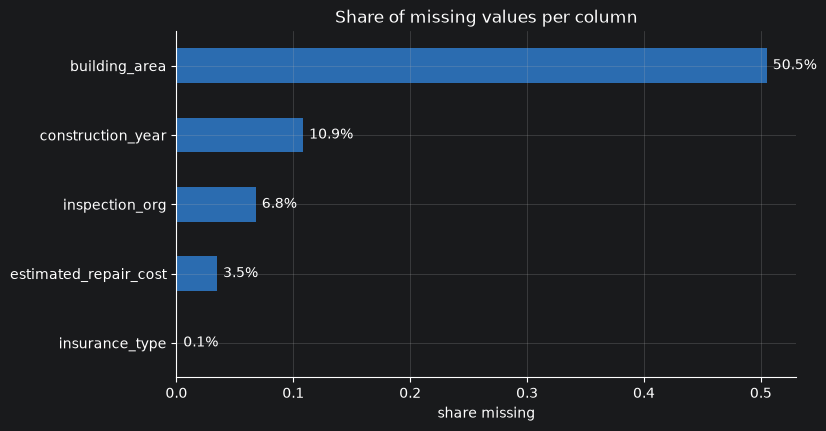

In [15]:
miss = raw_nodup.isna().mean().sort_values()
miss = miss[miss > 0]
ax = miss.plot.barh(color=BLUE)
ax.set(title="Share of missing values per column", xlabel="share missing")
for i, v in enumerate(miss):
    ax.text(v + .005, i, f"{v:.1%}", va="center")
plt.show()

**Takeaway:** `building_area` is missing for about half the rows, `construction_year` for about 11%, `inspection_org` for about 7% and `estimated_repair_cost` for about 3.5%. Missing indicators should be kept as features rather than imputing silently.

## 2. Data structure: claims, quotes, rows

rows  : 4698
claims: 2390
quotes: 3699
exact duplicate rows: 26


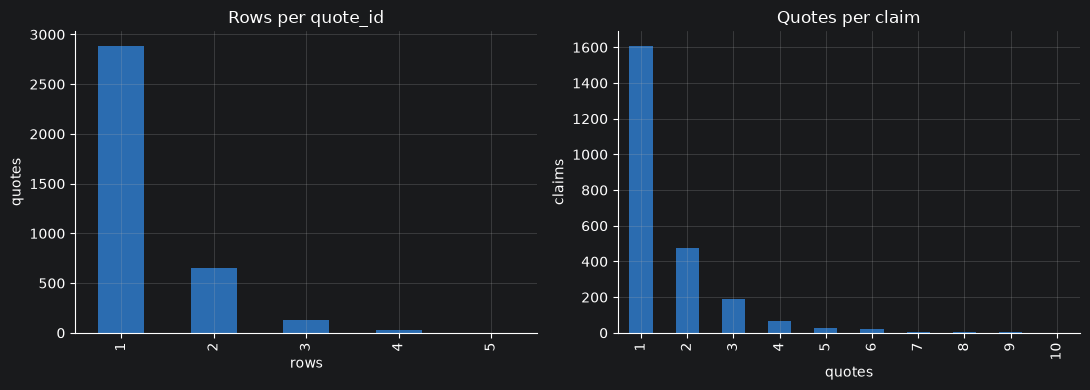

In [16]:
print("rows  :", len(raw))
print("claims:", raw.claim_id.nunique())
print("quotes:", raw.quote_id.nunique())
print("exact duplicate rows:", raw.duplicated().sum())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
raw.quote_id.value_counts().value_counts().sort_index().plot.bar(ax=axes[0], color=BLUE)
axes[0].set(title="Rows per quote_id", xlabel="rows", ylabel="quotes")
raw.groupby("claim_id").quote_id.nunique().value_counts().sort_index().plot.bar(ax=axes[1], color=BLUE)
axes[1].set(title="Quotes per claim", xlabel="quotes", ylabel="claims")
plt.tight_layout(); plt.show()

In [17]:
# Which columns vary WITHIN a quote that has several rows?
multi = raw[raw.quote_id.duplicated(keep=False)]
(multi.groupby("quote_id").nunique() > 1).mean().sort_values(ascending=False).to_frame("share of multi-row quotes where column varies")

,share of multi-row quotes where column varies
policyholder_cost,0.96
insurance_company_cost,0.95
inspection_type,0.31
building_type,0.30
insurance_type,0.26
inspection_org,0.04
building_geographical_location,0.03
claim_id,0.00
estimated_repair_cost,0.00
insurance_excess_amount,0.00


In [18]:
# Mix of quote events per claim
raw.groupby("claim_id").quote_event.apply(lambda s: " + ".join(sorted(set(s)))).value_counts().to_frame("claims")

,claims
quote_event,
preliminary quote,1330
final quote,748
final quote + preliminary quote,312


**Takeaway:** a quote can span several rows. The contractor cost, decision and review flag are constant within a quote, while the insurer/policyholder split and some categories vary. This looks like coverage lines. The decision unit is the **quote**, so the data is collapsed to one row per quote and split by `claim_id` for validation. Only about 13% of claims have both a preliminary and a final quote.

## 3. Cost columns

In [19]:
cost_cols = ["contractor_cost", "insurance_company_cost", "policyholder_cost", "estimated_repair_cost", "insurance_excess_amount"]
raw[cost_cols].describe(percentiles=[.05, .25, .5, .75, .95]).T

,count,mean,std,min,5%,25%,50%,75%,95%,max
contractor_cost,"4,698.00","74,537.64","61,543.14",0.00,"18,418.35","27,155.06","54,716.28","101,529.57","201,594.18","300,000.00"
insurance_company_cost,"4,698.00","81,024.02","77,901.39",0.00,"9,551.08","19,224.82","55,815.44","111,801.42","277,584.05","300,000.00"
policyholder_cost,"4,698.00","-8,439.06","72,253.55","-300,000.00","-182,603.89",6.72,"11,556.17","22,946.39","41,659.54","100,000.00"
estimated_repair_cost,"4,535.00","79,627.34","82,054.12",0.00,0.00,"30,000.00","50,000.00","90,000.00","260,000.00","400,000.00"
insurance_excess_amount,"4,698.00","7,522.78","8,520.14",0.00,0.00,"3,000.00","5,000.00","9,000.00","23,000.00","50,000.00"


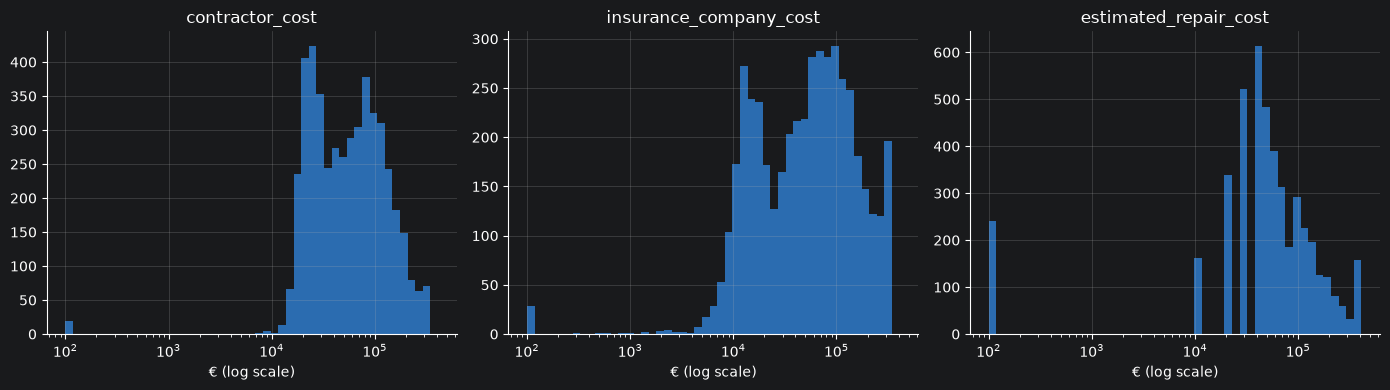

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
bins = np.logspace(2, np.log10(4.1e5), 50)
for ax, c in zip(axes, ["contractor_cost", "insurance_company_cost", "estimated_repair_cost"]):
    ax.hist(raw[c].clip(lower=100).dropna(), bins=bins, color=BLUE)
    ax.set(xscale="log", title=c, xlabel="€ (log scale)")
plt.tight_layout(); plt.show()

In [21]:
# Caps: values piling up at the maximum
for c in ["contractor_cost", "insurance_company_cost", "estimated_repair_cost", "inspection_images"]:
    mx = raw[c].max()
    print(f"{c:25s} max={mx:>10,.0f}   rows at max={int((raw[c] == mx).sum()):4d}   zeros={int((raw[c] == 0).sum())}")

contractor_cost           max=   300,000   rows at max=  63   zeros=12
insurance_company_cost    max=   300,000   rows at max= 188   zeros=27
estimated_repair_cost     max=   400,000   rows at max= 118   zeros=240
inspection_images         max=       300   rows at max=  53   zeros=24


In [22]:
# Accounting identity: insurer + policyholder = contractor?
gap = raw.insurance_company_cost + raw.policyholder_cost - raw.contractor_cost
print(f"identity holds (|gap| < €1) on {(gap.abs() < 1).mean():.1%} of rows")
print(f"policyholder_cost negative on {(raw.policyholder_cost < 0).mean():.1%} of rows")
raw.loc[gap.abs() >= 1, cost_cols].head()

identity holds (|gap| < €1) on 95.5% of rows
policyholder_cost negative on 22.9% of rows


,contractor_cost,insurance_company_cost,policyholder_cost,estimated_repair_cost,insurance_excess_amount
10,"282,196.64","300,000.00","-46,565.79","300,000.00",0
1503,"52,809.86","300,000.00","-300,000.00","120,000.00",3000
13,"88,695.63","300,000.00","-300,000.00","130,000.00",9000
1510,"37,204.23",0.00,"37,707.98","40,000.00",21000
2794,"22,784.22","300,000.00","-296,158.04","120,000.00",0


**Takeaway:** costs are heavily right-skewed, so model on the log scale. Values pile up at €300k (and 300 images), which suggests caps or truncation. `insurer + policyholder = contractor` holds for about 95% of rows. The other 5% are worth asking the business about. Insurer and policyholder cost are **outcomes** of processing, so they can't be used as model inputs.

## 4. Inspector estimate vs contractor quote

missing: 3.5%   zero: 238   multiple of €10k (of non-missing): 100.0%


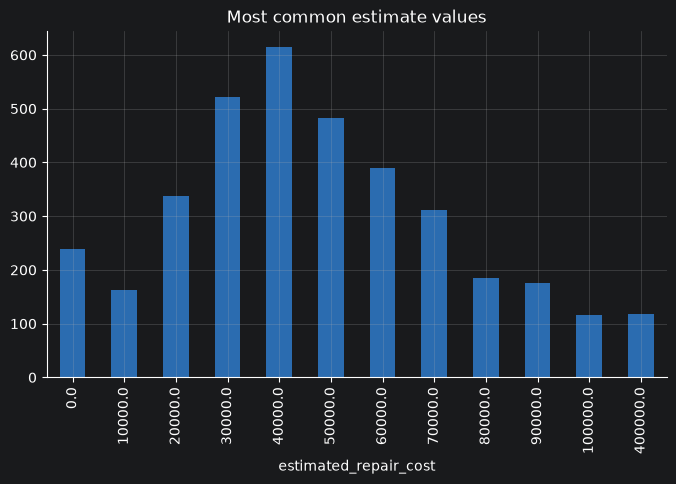

In [23]:
est = raw_nodup.estimated_repair_cost
print(f"missing: {est.isna().mean():.1%}   zero: {(est == 0).sum()}   "
      f"multiple of €10k (of non-missing): {(est.dropna() % 10_000 == 0).mean():.1%}")
est.value_counts().head(12).sort_index().plot.bar(color=BLUE, title="Most common estimate values")
plt.show()

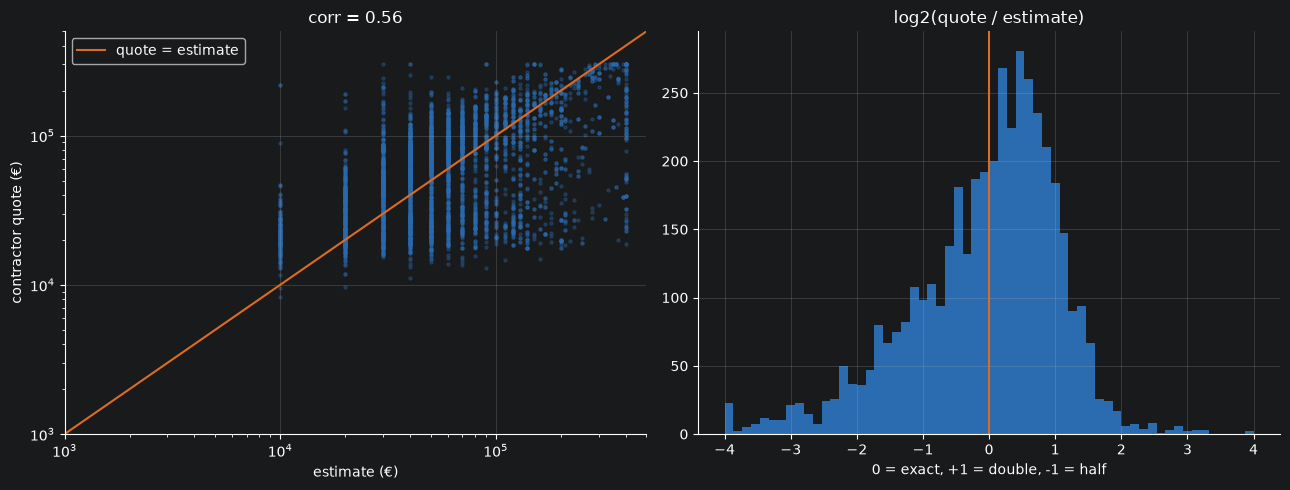

count   4,271.00
mean        1.24
std         0.99
min         0.00
10%         0.33
25%         0.63
50%         1.11
75%         1.63
90%         2.20
max        21.90
Name: ratio, dtype: float64

In [24]:
v = raw_nodup[raw_nodup.estimated_repair_cost > 0].copy()
v["ratio"] = v.contractor_cost / v.estimated_repair_cost

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(v.estimated_repair_cost, v.contractor_cost, s=5, alpha=.3, color=BLUE)
lim = [1e3, 5e5]; axes[0].plot(lim, lim, color=ORANGE, label="quote = estimate")
axes[0].set(xscale="log", yscale="log", xlim=lim, ylim=lim, xlabel="estimate (€)", ylabel="contractor quote (€)",
            title=f"corr = {v[['estimated_repair_cost','contractor_cost']].corr().iloc[0,1]:.2f}")
axes[0].legend()
axes[1].hist(np.log2(v.ratio.clip(1/16, 16)), bins=60, color=BLUE)
axes[1].axvline(0, color=ORANGE)
axes[1].set(title="log2(quote / estimate)", xlabel="0 = exact, +1 = double, -1 = half")
plt.tight_layout(); plt.show()
v.ratio.describe(percentiles=[.1, .25, .5, .75, .9])

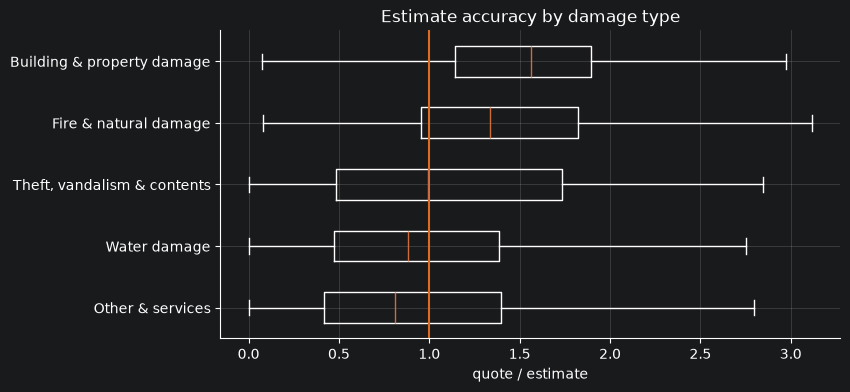

In [25]:
order = v.groupby("inspection_type").ratio.median().sort_values().index
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot([v.loc[v.inspection_type == t, "ratio"] for t in order], tick_labels=order, vert=False, showfliers=False)
ax.axvline(1, color=ORANGE); ax.set(xlabel="quote / estimate", title="Estimate accuracy by damage type")
plt.show()

**Takeaway:** the inspector estimate is a **coarse bucket** (every non-missing estimate is a multiple of €10k, and 240 are zero). It only loosely predicts the quote (correlation about 0.54; the middle 50% of quotes fall between 0.6× and 1.6× the estimate). That gap is the opportunity: a model of the "fair" cost can be much more precise than the inspector's bucket.

## 5. Building and inspection features

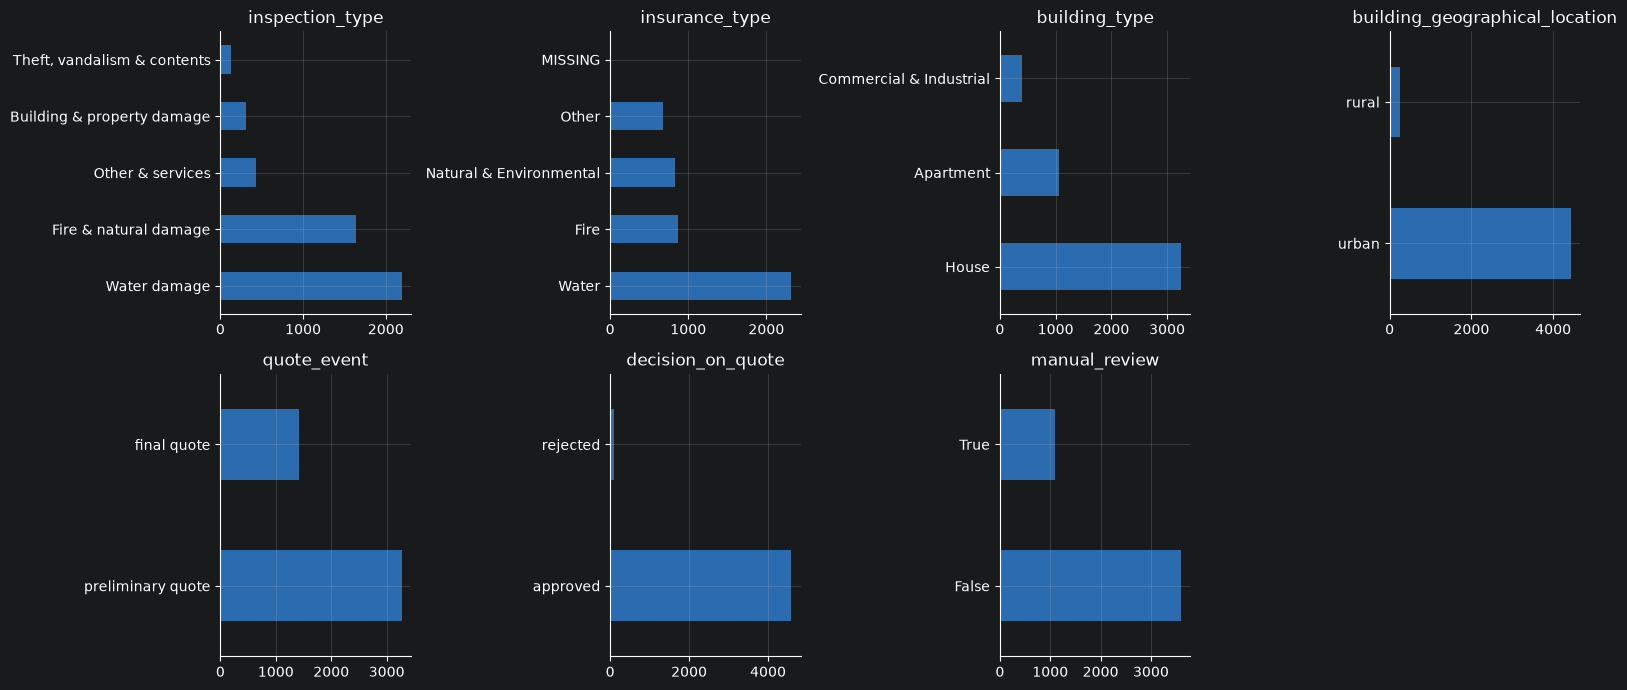

In [26]:
cats = ["inspection_type", "insurance_type", "building_type", "building_geographical_location", "quote_event", "decision_on_quote", "manual_review"]
fig, axes = plt.subplots(2, 4, figsize=(16, 7)); axes = axes.ravel()
for ax, c in zip(axes, cats):
    raw[c].fillna("MISSING").value_counts().plot.barh(ax=ax, color=BLUE); ax.set(title=c, ylabel="")
axes[-1].axis("off"); plt.tight_layout(); plt.show()

In [15]:
# Median contractor quote by category
for c in ["inspection_type", "insurance_type", "building_type", "building_geographical_location"]:
    display(raw.groupby(c).contractor_cost.agg(["size", "median", "mean"]).sort_values("median"))

,size,median,mean
inspection_type,,,
Other & services,429,"29,305.97","49,506.32"
Water damage,2192,"32,237.56","51,049.01"
Building & property damage,312,"42,030.51","48,488.96"
"Theft, vandalism & contents",128,"43,207.51","68,965.26"
Fire & natural damage,1637,"101,790.40","117,949.94"


,size,median,mean
insurance_type,,,
Water,2321,"33,263.73","51,283.93"
Other,674,"34,260.90","46,395.03"
Fire,867,"84,233.36","88,220.99"
Natural & Environmental,832,"141,318.90","147,669.18"


,size,median,mean
building_type,,,
House,3253,"46,660.49","68,374.35"
Apartment,1056,"67,158.76","80,494.39"
Commercial & Industrial,389,"93,956.15","109,907.36"


,size,median,mean
building_geographical_location,,,
urban,4434,"53,259.35","72,805.29"
rural,264,"83,220.53","103,633.13"


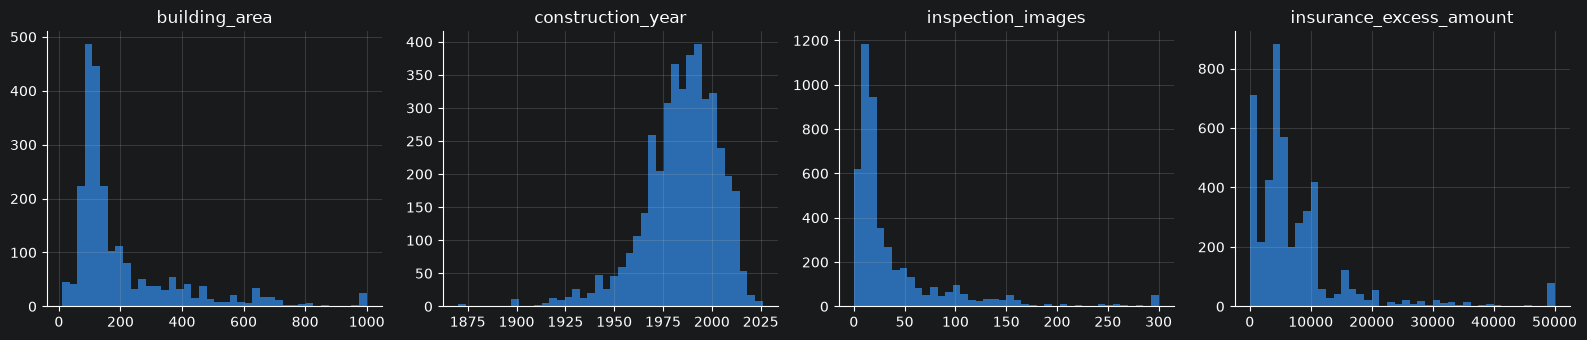

In [27]:
nums = ["building_area", "construction_year", "inspection_images", "insurance_excess_amount"]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, c in zip(axes, nums):
    ax.hist(raw[c].dropna(), bins=40, color=BLUE); ax.set(title=c)
plt.tight_layout(); plt.show()

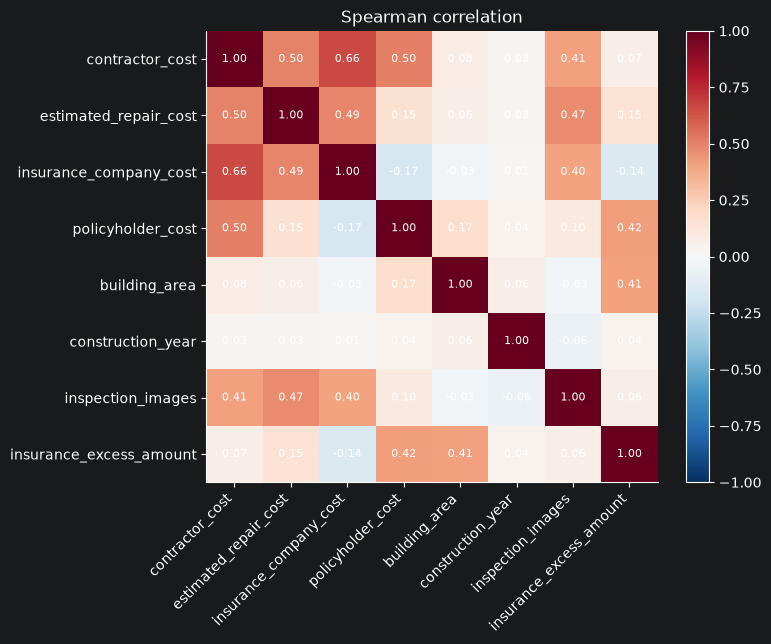

In [28]:
num_all = ["contractor_cost", "estimated_repair_cost", "insurance_company_cost", "policyholder_cost",
           "building_area", "construction_year", "inspection_images", "insurance_excess_amount"]
corr = raw[num_all].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(num_all)), num_all, rotation=45, ha="right"); ax.set_yticks(range(len(num_all)), num_all)
for i in range(len(num_all)):
    for j in range(len(num_all)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.grid(False); fig.colorbar(im); ax.set_title("Spearman correlation"); plt.tight_layout(); plt.show()

**Takeaway:** water damage is the largest segment. Building attributes add only weak signal on their own. The estimate is the strongest single predictor of the quote, but far from sufficient.

## 6. Inspection organisations

In [18]:
print("distinct orgs:", raw.inspection_org.nunique(), "| missing:", f"{raw.inspection_org.isna().mean():.1%}")
cnt = raw.inspection_org.value_counts()
print("orgs with < 10 rows:", (cnt < 10).sum(), "covering", f"{cnt[cnt < 10].sum() / len(raw):.1%} of rows")

distinct orgs: 252 | missing: 6.8%
orgs with < 10 rows: 110 covering 9.3% of rows


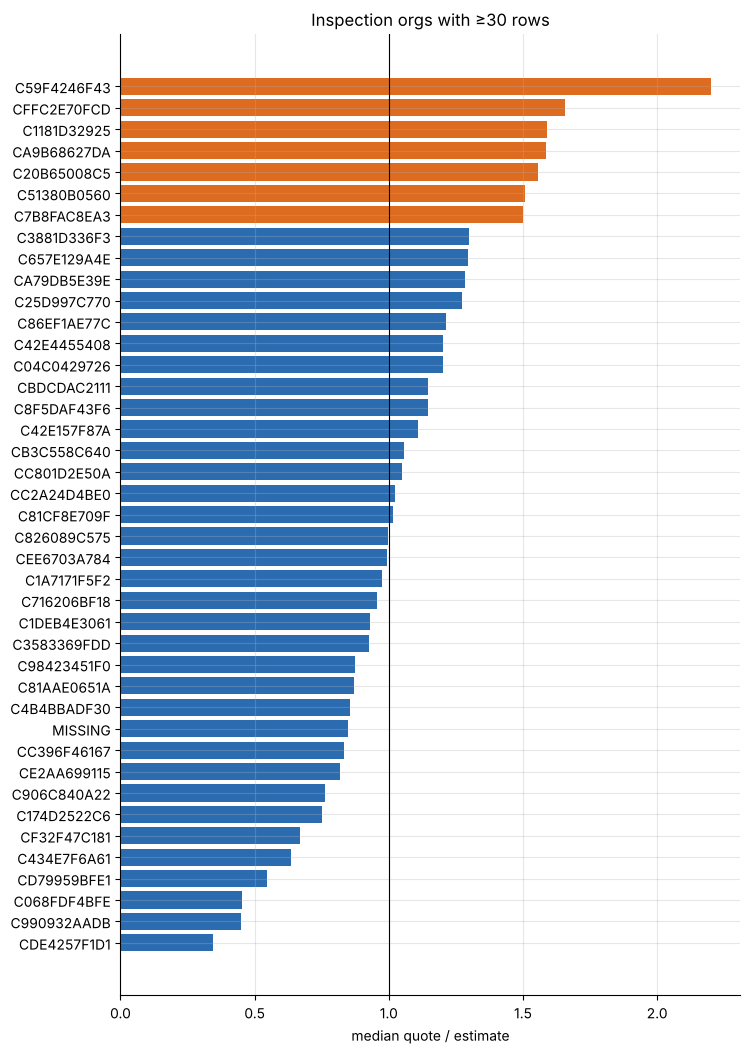

,n,median_ratio,median_quote
inspection_org,,,
CDE4257F1D1,30,0.34,"36,414.77"
C990932AADB,35,0.45,"51,550.90"
C068FDF4BFE,43,0.45,"31,825.50"
CD79959BFE1,33,0.55,"28,155.83"
C434E7F6A61,33,0.64,"41,103.34"
CF32F47C181,75,0.67,"60,203.55"
C174D2522C6,45,0.75,"30,442.63"
C906C840A22,43,0.76,"40,038.43"
CE2AA699115,31,0.82,"30,317.72"


In [19]:
org = (v.assign(inspection_org=v.inspection_org.fillna("MISSING"))
         .groupby("inspection_org").agg(n=("ratio", "size"), median_ratio=("ratio", "median"),
                                        median_quote=("contractor_cost", "median"))
         .query("n >= 30").sort_values("median_ratio"))
fig, ax = plt.subplots(figsize=(8, .28 * len(org) + 1))
ax.barh(org.index, org.median_ratio, color=[ORANGE if r > 1.3 else BLUE for r in org.median_ratio])
ax.axvline(1, color="black", lw=.8); ax.set(xlabel="median quote / estimate", title="Inspection orgs with ≥30 rows")
plt.show()
org

**Takeaway:** organisations differ systematically. Some see quotes at about half their estimate, others at nearly double. That's useful for **partner management** (estimate quality feedback), and a strong but high-cardinality feature: group the rare orgs and watch out for overfitting.

## 7. Manual review and decisions (selection bias)

In [29]:
pd.crosstab(raw.manual_review, raw.decision_on_quote, margins=True)

decision_on_quote,approved,rejected,All
manual_review,,,
False,3601,0,3601
True,992,105,1097
All,4593,105,4698


In [30]:
raw.groupby("manual_review").agg(rows=("quote_id", "size"),
                                 median_quote=("contractor_cost", "median"),
                                 median_insurer_cost=("insurance_company_cost", "median"),
                                 rejection_rate=("decision_on_quote", lambda s: (s == "rejected").mean()))

,rows,median_quote,median_insurer_cost,rejection_rate
manual_review,,,,
False,3601,"58,685.32","38,395.11",0.00
True,1097,"40,758.46","161,894.98",0.10


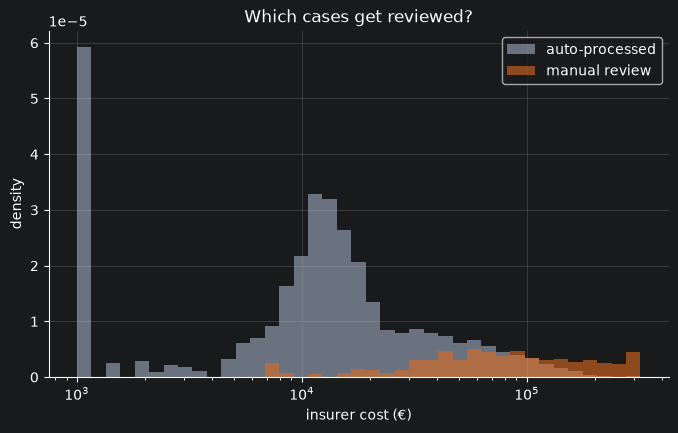

In [31]:
fig, ax = plt.subplots()
bins = np.logspace(3, np.log10(3.2e5), 40)
for flag, col, lab in [(False, GREY, "auto-processed"), (True, ORANGE, "manual review")]:
    ax.hist(raw.loc[raw.manual_review == flag, "insurance_company_cost"].clip(lower=1e3), bins=bins,
            alpha=.6, color=col, label=lab, density=True)
ax.set(xscale="log", xlabel="insurer cost (€)", ylabel="density", title="Which cases get reviewed?"); ax.legend()
plt.show()

In [32]:
# Review rate and rejection rate (within reviewed) by segment
rev = raw[raw.manual_review]
for c in ["inspection_type", "building_type", "quote_event"]:
    t = pd.DataFrame({"review_rate": raw.groupby(c).manual_review.mean(),
                      "reviewed_rows": rev.groupby(c).size(),
                      "rejection_rate_in_review": rev.groupby(c).decision_on_quote.apply(lambda s: (s == "rejected").mean())})
    display(t.sort_values("rejection_rate_in_review"))

,review_rate,reviewed_rows,rejection_rate_in_review
inspection_type,,,
Building & property damage,0.06,18,0.00
"Theft, vandalism & contents",0.25,32,0.06
Water damage,0.26,579,0.08
Other & services,0.26,110,0.09
Fire & natural damage,0.22,358,0.13


,review_rate,reviewed_rows,rejection_rate_in_review
building_type,,,
House,0.27,882,0.09
Apartment,0.13,141,0.13
Commercial & Industrial,0.19,74,0.15


,review_rate,reviewed_rows,rejection_rate_in_review
quote_event,,,
final quote,0.43,616,0.06
preliminary quote,0.15,481,0.15


near-zero quotes (< €100) among reviewed rows: 13 - excluded from the plot


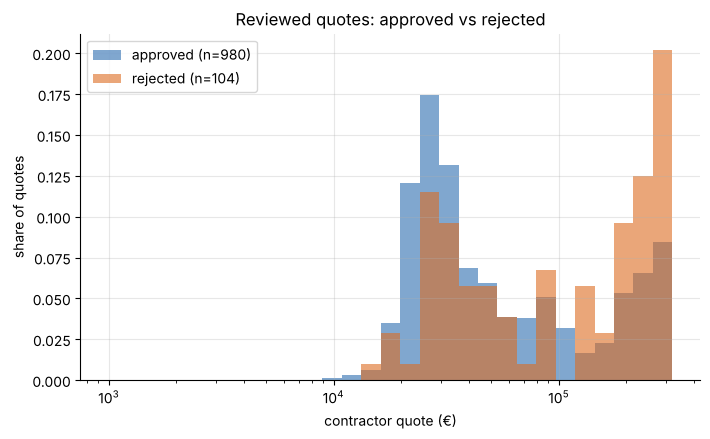

,count,mean,std,min,25%,50%,75%,90%,max
decision_on_quote,,,,,,,,,
approved,992.00,"86,561.43","89,820.22",0.00,"26,558.20","39,216.06","107,457.22","248,839.01","300,000.00"
rejected,105.00,"138,685.94","104,038.81",0.00,"35,254.09","126,596.28","229,526.30","280,963.25","300,000.00"


In [24]:
>z# Do rejected quotes look more expensive than approved ones (within reviewed)?
near_zero = rev.contractor_cost < 100
print(f"near-zero quotes (< €100) among reviewed rows: {near_zero.sum()} - excluded from the plot")
fig, ax = plt.subplots()
for d, col in [("approved", BLUE), ("rejected", ORANGE)]:
    s = rev.loc[(rev.decision_on_quote == d) & ~near_zero, "contractor_cost"]
    ax.hist(s, bins=np.logspace(3, np.log10(3.2e5), 30), alpha=.6, color=col,
            weights=np.full(len(s), 1 / len(s)), label=f"{d} (n={len(s)})")
ax.set(xscale="log", xlabel="contractor quote (€)", ylabel="share of quotes",
       title="Reviewed quotes: approved vs rejected"); ax.legend()
plt.show()
rev.groupby("decision_on_quote").contractor_cost.describe(percentiles=[.25, .5, .75, .9])

**Takeaway (the most important finding):**
- **All rejections happen in manually reviewed cases**, at a rate of about 10%. Auto-processed quotes are never rejected because nobody checks them, not because they are fine.
- **Review is not random.** Reviewed cases have about 4× higher insurer cost. A model trained on rejections learns from a biased sample, so its savings estimates for auto-processed quotes are extrapolation.
- Rejected quotes skew towards the **largest** amounts (heavier tail above €100k), which is why "review the biggest quotes first" is a strong baseline.
- There are only about 100 rejected rows (70 quotes), which is very little signal. Keep models simple and regularised.
- **Recommendation:** audit a random sample of auto-approved quotes to get unbiased labels.

## 8. Preliminary → final quotes

claims with both: 312 | final > preliminary: 52.6% | median change ×1.01


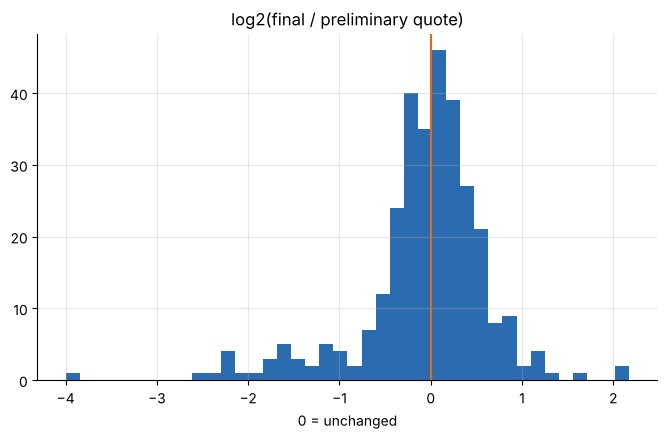

In [25]:
pre = raw[raw.quote_event == "preliminary quote"].drop_duplicates("claim_id", keep="first")
fin = raw[raw.quote_event == "final quote"].drop_duplicates("claim_id", keep="last")
m = pre.merge(fin, on="claim_id", suffixes=("_pre", "_fin"))
m["change"] = m.contractor_cost_fin / m.contractor_cost_pre
print(f"claims with both: {len(m)} | final > preliminary: {(m.change > 1).mean():.1%} | median change ×{m.change.median():.2f}")
fig, ax = plt.subplots()
ax.hist(np.log2(m.change.clip(1/16, 16)), bins=40, color=BLUE); ax.axvline(0, color=ORANGE)
ax.set(title="log2(final / preliminary quote)", xlabel="0 = unchanged"); plt.show()

**Takeaway:** only about 300 claims have both stages. The median change is roughly zero, but the spread is large in both directions. Price drift between stages is a possible later signal, but there's too little data for now. `quote_event` and the quote's sequence number are used as features.

## 9. Summary: data limitations and implications for modelling

| Finding | Implication |
|---|---|
| Several rows per quote; multiple quotes per claim; 26 duplicate rows | Collapse to quote level, deduplicate, **group CV folds by `claim_id`** |
| Insurer/policyholder cost and decision are outcomes | Exclude from features (leakage) |
| Costs are skewed and capped at €300k | Model `log(cost)`; flag capped rows |
| Estimate is a coarse €10k bucket, sometimes zero or missing | A "fair-cost" model can improve on it; add missing/zero flags |
| `building_area` 50% missing, `construction_year` 11% | Missing indicators; tree models handle NaN |
| 252 inspection orgs, large systematic differences | Group rare orgs; risk of overfitting; separate partner-feedback lever |
| Rejections only in reviewed cases; review targets large claims | **Selection bias**: labels are biased, savings on auto cases are unproven |
| About 70 rejected quotes | Simple, regularised classifier; evaluate in € caught per review budget against simple rules |
| No dates; no "approved amount after review" | Can't check drift or measure savings directly, so ask the business to start recording these |

**Next:** `python run_pipeline.py` trains the fair-cost and rejection models on these decisions (see `README.md`).